In [6]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
from tkinter.ttk import Separator

riscaldamento = np.genfromtxt(
    f"dataset/dataset_eltek/prova_phon/2026-07-02_Prova Housing-4 termocoppie_Phon_Riscaldamento.csv", 
    delimiter=";",
    skip_header=1,
    usecols=(0,1,2,3,4)
)
raffreddamento = np.genfromtxt(
    f"dataset/dataset_eltek/prova_phon/2026-07-02_Prova Housing-4 termocoppie_Phon_Raffreddamento.csv", 
    delimiter=";",
    skip_header=1,
    usecols=(0,1,2,3,4)
)

In [8]:
# Temperature shiftate rispetto all'ambiente

T_amb_mean = np.mean(riscaldamento[:,4])

Theta_0 = riscaldamento[:,1] - T_amb_mean
Theta_1 = riscaldamento[:,2] - T_amb_mean
Theta_2 = riscaldamento[:,3] - T_amb_mean
Theta_3 = riscaldamento[:,4] - T_amb_mean

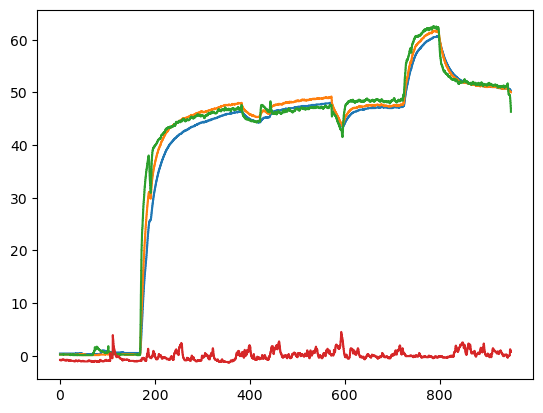

In [9]:
plt.plot(riscaldamento[:,0], Theta_0)
plt.plot(riscaldamento[:,0], Theta_1)
plt.plot(riscaldamento[:,0], Theta_2)
plt.plot(riscaldamento[:,0], Theta_3)

In [10]:
# Parametri simulazione
L = 0.003 # (metri)
Tf = riscaldamento[-1,0]
nt = np.size(Theta_0)
D = 0.005
wanted_r = 0.1
h = 1

from src.Heat1DCrankNicolson import Heat1DCrankNicolson

# Inizializza solver
solver = Heat1DCrankNicolson(L,Tf,nt,D,h,wanted_r=wanted_r)
solver.info()

_, n_eff = solver.diffusion_time()

from src.TikhonovHandler import TikhonovHandler, reconstruction_error_plot
th = TikhonovHandler(solver)

ZeroDivisionError: float division by zero